# A/B-тест системы достижений
**Производственная практика ПП.01 и ПП.02** · 4–24 мая 2026

**Вопрос.** Улучшает ли геймификация удержание и завершение курса? A — старый интерфейс, B — интерфейс с достижениями. Единица анализа — ученик. Две измеримые целевые метрики — Retention D7 и D14. Завершение курса оценить напрямую по этой выгрузке нельзя.

**Запуск.** Поместите оригинальные CSV в папку «data» рядом с ноутбуком, установите «pandas», «numpy», «Pillow» и запустите все ячейки в Python 3. В переменной DATA_DIR можно указать другой путь. В сохранённых выводах только агрегаты.

In [1]:
from pathlib import Path
from math import asin, erfc, sqrt, sin
from statistics import NormalDist

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

DATA_DIR = Path("data")
START = pd.Timestamp("2026-05-04")
END = START + pd.Timedelta(days=21)
ACTIVITY = ["login", "homework_started", "homework_completed"]
RETURNS = {"D7": "return_visit_d7", "D14": "return_visit_d14"}
ALPHA = 0.05
BOT_LIMIT = 100

users_raw = pd.read_csv(DATA_DIR / "ab_test_users_groups.csv", dtype={"user_id": "string"})
events_raw = pd.read_csv(DATA_DIR / "ab_test_events.csv", dtype={"user_id": "string"})
print(f"Строки с назначениями: {len(users_raw):,}. Строки событий: {len(events_raw):,}.")

Строки с назначениями: 6,008. Строки событий: 179,330.


## 1. Очистка и сверка сплита
Убираем точные повторы. Пользователей с противоречивым назначением исключаем из обеих групп: исходное назначение неизвестно. Проверяем формат даты регистрации, допустимые классы, состав событий, окно эксперимента и ключи при соединении.

Флаг возможного бота — больше 100 обычных событий за 21 день. Порог выбран по резкому разрыву в распределении объёма активности, без сравнения результатов A и B. Это эвристика. Ниже сравним итог с результатом при сохранении таких аккаунтов.

In [2]:
users = users_raw.drop_duplicates().copy()
events = events_raw.drop_duplicates().copy()
events["timestamp"] = pd.to_datetime(events["timestamp"], errors="coerce")
signup = pd.to_datetime(users["signup_date"], errors="coerce")
assert users["user_id"].notna().all() and users["group"].isin(["A", "B"]).all()
assert users["grade"].isin(range(5, 12)).all() and signup.lt(START).all()

overlap = users.groupby("user_id")["group"].nunique().gt(1)
ambiguous_ids = overlap[overlap].index
eligible = users.loc[~users.user_id.isin(ambiguous_ids)].set_index("user_id", verify_integrity=True)
valid_time = events.timestamp.ge(START) & events.timestamp.lt(END)
valid_type = events.event_type.isin(ACTIVITY + list(RETURNS.values()))
known_id = events.user_id.isin(users.user_id)
usable = events.loc[valid_time & valid_type & known_id].copy()
linked = usable.merge(eligible[["group"]], left_on="user_id", right_index=True,
                      how="inner", validate="many_to_one")

volume = (linked.loc[linked.event_type.isin(ACTIVITY)].groupby("user_id").size()
          .reindex(eligible.index, fill_value=0))
bot_flag = volume.gt(BOT_LIMIT)
clean = eligible.loc[~bot_flag]
logs = linked.loc[linked.user_id.isin(clean.index)]
for day, event_type in [(7, RETURNS["D7"]), (14, RETURNS["D14"])]:
    days = logs.loc[logs.event_type.eq(event_type), "timestamp"].dt.normalize()
    assert days.eq(START + pd.Timedelta(days=day)).all()

audit = pd.Series({
    "Точные дубликаты назначений": len(users_raw) - len(users),
    "Точные дубликаты событий": len(events_raw) - len(events),
    "В обеих группах, учеников": len(ambiguous_ids),
    "Нераспознанное время или вне окна, событий": int((~valid_time).sum()),
    "Неизвестный тип, событий": int((~valid_type).sum()),
    "Пользователь без назначения, событий": int((~known_id).sum()),
    "События исключённых из-за сплита": len(usable) - len(linked),
    "Аномальные аккаунты": int(bot_flag.sum()),
    "События аномальных аккаунтов": len(linked) - len(logs),
    "Максимум событий ниже порога": int(volume[~bot_flag].max()),
    "Минимум событий выше порога": int(volume[bot_flag].min()),
    "События для анализа": len(logs),
})
display(audit.to_frame("Количество"))

def split_check(frame):
    a, b = frame.group.value_counts().reindex(["A", "B"])
    expected = (a + b) / 2
    chi2 = ((a - expected)**2 + (b - expected)**2) / expected
    return int(a), int(b), chi2, erfc(sqrt(chi2 / 2))

srm = pd.DataFrame([split_check(eligible), split_check(clean)],
                   index=["До фильтра активности", "После фильтра активности"],
                   columns=["A", "B", "χ²", "p-value"])
display(srm.round(4))
display(pd.crosstab(clean.grade, clean.group))

,Количество
Точные дубликаты назначений,0
Точные дубликаты событий,2
"В обеих группах, учеников",8
"Нераспознанное время или вне окна, событий",0
"Неизвестный тип, событий",0
"Пользователь без назначения, событий",0
События исключённых из-за сплита,217
Аномальные аккаунты,12
События аномальных аккаунтов,9278
Максимум событий ниже порога,51


,A,B,χ²,p-value
До фильтра активности,2997,2995,0.0007,0.9794
После фильтра активности,2992,2988,0.0027,0.9587


group,A,B
grade,,
5,446,416
6,446,462
7,402,435
8,454,431
9,430,379
10,409,438
11,405,427


В ТЗ нет планового соотношения групп. Для SRM предполагаем 50:50 и применяем критерий Пирсона с одной степенью свободы. Первый расчёт проверяет однозначные назначения, второй показывает, изменилось ли соотношение после фильтра. SRM оценивает размеры групп. Проверка не восстанавливает назначения конфликтных записей и не подтверждает все свойства рандомизации.

## 2. Метрики на уровне ученика
**D7 / D14** — наличие соответствующего события в фиксированный день от начала эксперимента. Знаменатель — все ученики с валидным назначением в выбранной выборке, включая тех, у кого нет события возврата. Дату регистрации для отсчёта не используем.

**Воронка** — назначен, вошёл, начал ДЗ после входа, выполнил хотя бы одно ДЗ после старта. Шаги соединяем по ученику и времени, разрешая одинаковое время. Без ID задания нельзя связать старт и завершение конкретного задания. Без события завершения модуля, ID модуля или списка обязательных задач нельзя получить Completion Rate курса или процент выполненных задач. Выполненное ДЗ служит наблюдаемым шагом, число таких событий описывает активность.

In [3]:
METRICS = {
    "D7": "Удержание D7", "D14": "Удержание D14", "f_done": "Выполнил ДЗ в воронке",
    "done3": "≥3 событий выполнения", "done5": "≥5 событий выполнения"
}

def student_metrics(assignments, activity):
    counts = (activity.groupby(["user_id", "event_type"]).size().unstack(fill_value=0)
              .reindex(index=assignments.index, columns=ACTIVITY + list(RETURNS.values()),
                       fill_value=0))
    result = assignments.join(counts)
    result["assigned"] = True
    result["D7"] = result[RETURNS["D7"]].gt(0)
    result["D14"] = result[RETURNS["D14"]].gt(0)
    result["done3"] = result.homework_completed.ge(3)
    result["done5"] = result.homework_completed.ge(5)

    previous = None
    for step, event_type in zip(["f_login", "f_start", "f_done"], ACTIVITY):
        candidates = activity.loc[activity.event_type.eq(event_type), ["user_id", "timestamp"]]
        if previous is not None:
            candidates = candidates.join(previous.rename("prior"), on="user_id")
            candidates = candidates.loc[candidates.timestamp.ge(candidates.prior)]
        previous = candidates.groupby("user_id").timestamp.min()
        result[step] = result.index.isin(previous.index)
    return result

students = student_metrics(clean, logs)
with_outliers = student_metrics(eligible, linked)
steps = {
    "assigned": "Назначены", "f_login": "Вошли",
    "f_start": "Начали ДЗ после входа", "f_done": "Выполнили ДЗ после старта"
}
funnel_counts = students.groupby("group")[list(steps)].sum().T.rename(index=steps)
funnel_rates = funnel_counts.div(funnel_counts.iloc[0]) * 100
funnel_previous = funnel_counts.div(funnel_counts.shift()) * 100
display(pd.concat({"Ученики": funnel_counts, "% от назначенных": funnel_rates.round(2),
                   "% от предыдущего шага": funnel_previous.round(2)}, axis=1))
assert (np.diff(funnel_counts.to_numpy(), axis=0) <= 0).all()
assert len(students) == students.index.nunique()

Ученики        ... % от предыдущего шага        
group                           A     B  ...                     A       B
Назначены                    2992  2988  ...                   NaN     NaN
Вошли                        2992  2988  ...                100.00  100.00
Начали ДЗ после входа        2992  2988  ...                100.00  100.00
Выполнили ДЗ после старта    2921  2953  ...                 97.63   98.83

[4 rows x 6 columns]

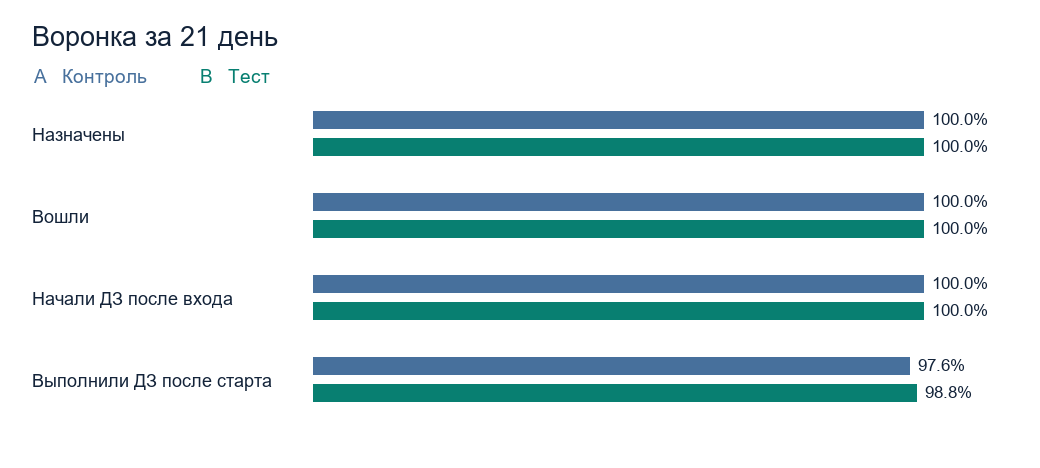

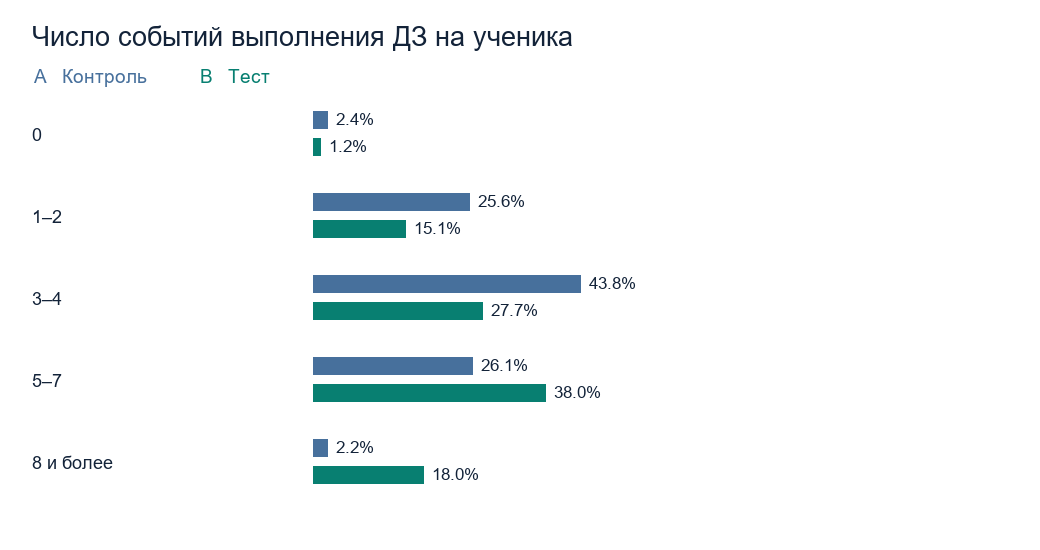

In [4]:
# Графики сохраняются прямо в выводах ноутбука.
def font(size):
    for candidate in ("arial.ttf", "DejaVuSans.ttf",
                      "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"):
        try:
            return ImageFont.truetype(candidate, size)
        except OSError:
            continue
    return ImageFont.load_default(size=size)

def grouped_bars(table, title, limit, suffix):
    image = Image.new("RGB", (1040, 140 + 82 * len(table)), "white")
    draw = ImageDraw.Draw(image)
    ink, colors = "#132339", {"A": "#47709C", "B": "#087F71"}
    draw.text((32, 21), title, fill=ink, font=font(27))
    for j, group in enumerate(("A", "B")):
        draw.text((34 + 166*j, 65), f"{group}   {'Контроль' if j == 0 else 'Тест'}",
                  fill=colors[group], font=font(19))
    for i, (label, values) in enumerate(table.iterrows()):
        y = 111 + 82*i
        draw.text((32, y + 13), str(label), fill=ink, font=font(18))
        for j, group in enumerate(("A", "B")):
            value = float(values[group])
            x0, y0 = 313, y + 27*j
            x1 = x0 + round(610 * value / limit)
            if x1 > x0:
                draw.rectangle((x0, y0, x1, y0 + 17), fill=colors[group])
            draw.text((x1 + 9, y0 - 2), f"{value:.1f}{suffix}", fill=ink, font=font(17))
    return image

display(grouped_bars(funnel_rates, "Воронка за 21 день", 100, "%"))
bins = pd.cut(students.homework_completed, [-1, 0, 2, 4, 7, float("inf")],
              labels=["0", "1–2", "3–4", "5–7", "8 и более"])
distribution = pd.crosstab(bins, students.group, normalize="columns") * 100
display(grouped_bars(distribution, "Число событий выполнения ДЗ на ученика", 100, "%"))

## 3. Эффект и точность оценки
Для бинарных метрик используем двусторонний z-тест двух долей с объединённой оценкой дисперсии под H0. Нулевая гипотеза — вероятности одинаковы. Альтернатива — различаются. Ожидаемые числа успехов и неуспехов достаточны для нормального приближения в общих сравнениях. Доверительный интервал разницы строим методом Ньюкомба на основе интервалов Уилсона.

Для двух целевых метрик применяем поправку Холма. Интервалы 95% индивидуальные. Метрики выполнения ДЗ рассматриваем как разведочные. MDE — положительная разница, которую можно обнаружить с мощностью 80% при фактических размерах групп, базовом уровне A и двустороннем α = 0,025 для целевых метрик (консервативное планирование по Бонферрони). Для разведочных метрик используем α = 0,05. MDE оцениваем приближённо через эффект Коэна h. Это оценка чувствительности дизайна. Порог коммерческой целесообразности задаёт продуктовая команда.

In [5]:
normal = NormalDist()

def wilson(p, n, alpha=ALPHA):
    z = normal.inv_cdf(1 - alpha / 2)
    denominator = 1 + z*z/n
    center = (p + z*z/(2*n)) / denominator
    radius = z * sqrt(p*(1-p)/n + z*z/(4*n*n)) / denominator
    return center - radius, center + radius

def power(h, n_a, n_b, alpha):
    shift = h / sqrt(1/n_a + 1/n_b)
    critical = normal.inv_cdf(1 - alpha/2)
    return normal.cdf(-critical - shift) + normal.cdf(shift - critical)

def mde(p_a, n_a, n_b, alpha):
    base = asin(sqrt(p_a))
    lo, hi = 0., 2*(asin(1) - base)
    if power(hi, n_a, n_b, alpha) < .80:
        return np.nan
    for _ in range(45):
        mid = (lo + hi) / 2
        if power(mid, n_a, n_b, alpha) < .80:
            lo = mid
        else:
            hi = mid
    return sin(base + hi/2)**2 - p_a

def difference(frame, metric):
    grouped = frame.groupby("group")[metric]
    n_a, n_b = grouped.size().reindex(["A", "B"])
    s_a, s_b = grouped.sum().reindex(["A", "B"])
    a, b = s_a/n_a, s_b/n_b
    pooled = (s_a + s_b)/(n_a + n_b)
    se = sqrt(pooled*(1-pooled)*(1/n_a + 1/n_b))
    delta = b - a
    p = erfc(abs(delta/se)/sqrt(2)) if se else 1.
    la, ua = wilson(a, n_a)
    lb, ub = wilson(b, n_b)
    return {
        "n_A": int(n_a), "n_B": int(n_b), "s_A": int(s_a), "s_B": int(s_b),
        "A, %": 100*a, "B, %": 100*b, "Δ, п.п.": 100*delta,
        "ДИ от": 100*(delta - sqrt((b-lb)**2 + (ua-a)**2)),
        "ДИ до": 100*(delta + sqrt((ub-b)**2 + (a-la)**2)),
        "p": p, "MDE, п.п.": 100*mde(a, n_a, n_b, ALPHA/2 if metric in RETURNS else ALPHA)
    }

results = pd.DataFrame({metric: difference(students, metric) for metric in METRICS}).T
p_sorted = results.loc[list(RETURNS), "p"].sort_values()
results["p Холма"] = (p_sorted * np.arange(len(p_sorted), 0, -1)).cummax().clip(upper=1)
result_table = results.rename(index=METRICS).round(2)
for column in ["p", "p Холма"]:
    result_table[column] = results.rename(index=METRICS)[column].map(
        lambda value: f"{value:.3g}" if pd.notna(value) else "—")
for column in ["n_A", "n_B", "s_A", "s_B"]:
    result_table[column] = result_table[column].astype(int)
display(result_table)

sensitivity = pd.DataFrame({
    "После очистки, п.п.": results.loc[list(RETURNS), "Δ, п.п."],
    "С аномальными аккаунтами, п.п.": {
        m: difference(with_outliers, m)["Δ, п.п."] for m in RETURNS
    }
})
display(sensitivity.round(2))

,n_A,n_B,s_A,s_B,"A, %","B, %","Δ, п.п.",ДИ от,ДИ до,p,"MDE, п.п.",p Холма
Удержание D7,2992,2988,2175,2330,72.69,77.98,5.28,3.10,7.46,2.13e-06,3.48,2.13e-06
Удержание D14,2992,2988,862,1083,28.81,36.24,7.43,5.06,9.80,8.44e-10,3.67,1.69e-09
Выполнил ДЗ в воронке,2992,2988,2921,2953,97.63,98.83,1.20,0.54,1.89,0.00043,0.98,—
≥3 событий выполнения,2992,2988,2156,2502,72.06,83.73,11.68,9.59,13.75,1.45e-27,3.19,—
≥5 событий выполнения,2992,2988,847,1674,28.31,56.02,27.72,25.29,30.09,2.01e-104,3.32,—


,"После очистки, п.п.","С аномальными аккаунтами, п.п."
D7,5.28,5.26
D14,7.43,7.46


## 4. Эффект по школьным классам
Возраст отсутствует. Используем класс и показываем все классы, а также три укрупнённые группы. Эти сравнения разведочные. Интервалы индивидуальные, анализ не был задан заранее. Для решения о запуске на выбранный сегмент потребуется подтверждающий тест.

In [6]:
bands = pd.cut(students.grade, [4, 7, 9, 11], labels=["5–7", "8–9", "10–11"])

def retention_segments(groups):
    rows = []
    for label, frame in groups:
        for metric in RETURNS:
            effect = difference(frame, metric)
            rows.append({"Класс": str(label), "Метрика": metric,
                         **{k: effect[k] for k in ["n_A", "n_B", "A, %", "B, %",
                                                    "Δ, п.п.", "ДИ от", "ДИ до"]}})
    return pd.DataFrame(rows)

by_grade = retention_segments(students.groupby("grade"))
by_band = retention_segments(students.groupby(bands, observed=True))
display(by_grade.round(2))
display(by_band.round(2))

,Класс,Метрика,n_A,n_B,"A, %","B, %","Δ, п.п.",ДИ от,ДИ до
0,5,D7,446,416,72.87,82.45,9.58,4.02,15.04
1,5,D14,446,416,28.48,43.51,15.03,8.64,21.28
2,6,D7,446,462,75.56,86.58,11.02,5.94,16.07
3,6,D14,446,462,30.04,45.89,15.84,9.55,21.95
4,7,D7,402,435,70.65,84.60,13.95,8.33,19.52
5,7,D14,402,435,26.12,43.91,17.79,11.36,23.99
6,8,D7,454,431,73.57,77.49,3.93,-1.75,9.55
7,8,D14,454,431,28.85,34.57,5.72,-0.41,11.80
8,9,D7,430,379,71.63,78.36,6.74,0.74,12.61
9,9,D14,430,379,29.30,34.56,5.26,-1.16,11.67


,Класс,Метрика,n_A,n_B,"A, %","B, %","Δ, п.п.",ДИ от,ДИ до
0,5–7,D7,1294,1313,73.11,84.62,11.51,8.39,14.60
1,5–7,D14,1294,1313,28.28,44.48,16.19,12.53,19.80
2,8–9,D7,884,810,72.62,77.90,5.28,1.16,9.35
3,8–9,D14,884,810,29.07,34.57,5.50,1.06,9.92
4,10–11,D7,814,865,72.11,67.98,-4.14,-8.49,0.25
5,10–11,D14,814,865,29.36,25.32,-4.04,-8.30,0.22


## 5. Рекомендация продуктовой команде
**Отправить механику на доработку и провести подтверждающий тест перед массовым запуском.**

- Общий прирост удержания по D7 и D14 проходит поправку Холма. Для когорты из 1 000 сопоставимых учеников оценки соответствуют примерно 53 дополнительным возвратам на D7 и 74 на D14. Это проекция экспериментальной разницы на такой же состав пользователей. Коммерческий порог в ТЗ отсутствует.
- В 5–7 классах эффект удержания заметно выше. В 10–11 классах оценки по обеим метрикам отрицательны. Используем этот сигнал для приоритизации доработки и проверки по заранее заданным сегментам.
- Следующий тест стоит стратифицировать по классу и заранее согласовать длительность, практически значимый прирост, допустимое ухудшение удержания по сегментам и правило остановки. В логах нужны события полного прохождения модуля и курса, идентификаторы заданий и стабильное назначение в группу.
- В выгрузке доступен финальный срез. По нему нельзя проверить, смотрела ли команда на промежуточные p-value и меняла ли правила остановки.